<a href="https://colab.research.google.com/github/Yamuna1911/FDP/blob/main/Confusion_Matrix.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay


In [6]:
# Load data
df = sns.load_dataset("titanic")
df = df[["survived", "pclass", "sex", "age", "fare"]].dropna()
df["sex"] = df["sex"].map({"male": 0, "female": 1})

X = df.drop("survived", axis=1)
y = df["survived"]

In [7]:
# Split and train
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

Confusion Matrix:
 [[68 19]
 [16 40]]
TP: 40 TN: 68 FP: 19 FN: 16
Accuracy: 0.7552447552447552


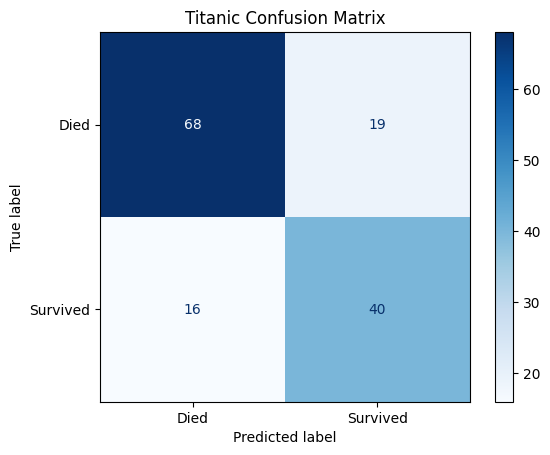

In [4]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

TN, FP, FN, TP = cm.ravel()
print("TP:", TP, "TN:", TN, "FP:", FP, "FN:", FN)
print("Accuracy:", accuracy_score(y_test, y_pred))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Died", "Survived"])
disp.plot(cmap="Blues")
plt.title("Titanic Confusion Matrix")
plt.show()